# ECG-Net Phase 1 — M1: data pipeline, EDA, models, evaluation
Source of truth: `docs/phase1/PHASE1_PLAN.md` (section 2) and `docs/phase1/M1_IMPLEMENTATION_PLAN.md`.
All logic lives in `src/`; this notebook only calls it and shows results. Heavy results are cached in `results/`.
Task: 6-class single-diagnosis classification (NSR, RBBB, AF, IAVB, PAC, SB) from hand-crafted features of 12-lead ECGs.

## 0. Setup

In [1]:
%load_ext autoreload
%autoreload 2
import warnings, json, subprocess, sys, os, ast
warnings.filterwarnings("ignore")
import pathlib
ROOT = pathlib.Path.cwd(); ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)      # make `src` importable from notebooks/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

SEED = 42            # random_state everywhere
N_JOBS = 10
RUN_HEAVY = False    # True re-runs the model sweeps (scripts/run_models.py); False loads cached results

from src.loaders import PROJECT_ROOT, RESULTS_DIR, DATA_DIR, MODELS_DIR, FIG_DIR
from src import loaders, labels as lab_mod, splits as sp, features as ft, evaluate as ev, models as md_, eda
FIG = FIG_DIR

import sklearn, lightgbm, neurokit2
print("sklearn", sklearn.__version__, "| lightgbm", lightgbm.__version__, "| neurokit2", neurokit2.__version__)
try:
    import torch; print("torch.cuda.is_available():", torch.cuda.is_available(), "(Phase 1 is classical ML on CPU; GPU not needed)")
except ImportError:
    print("torch not installed (not needed in Phase 1)")

sklearn 1.9.1 | lightgbm 4.7.0 | neurokit2 0.3.0


torch.cuda.is_available(): True (Phase 1 is classical ML on CPU; GPU not needed)


## 1. Data loading (headers only)

In [2]:
meta = loaders.scan_records()          # cached in results/records_meta.parquet
print(len(meta), "records")
meta.groupby("source").agg(n=("record_id", "size"), fs=("fs", lambda s: sorted(set(map(int, s)))),
    dur_min_s=("duration_s", "min"), dur_max_s=("duration_s", "max"), age_missing=("age", lambda s: int(s.isna().sum())))

43101 records


,n,fs,dur_min_s,dur_max_s,age_missing
source,,,,,
cpsc_2018,6877,[500],6.0,144.000,9
cpsc_2018_extra,3453,[500],8.0,98.000,3
georgia,10344,[500],5.0,10.000,77
ptb,516,[1000],32.0,120.012,9
ptb-xl,21837,[500],10.0,10.000,293
st_petersburg_incart,74,[257],1800.0,1800.000,0


## 2. Label mapping and the 6-class task table

In [3]:
print(lab_mod.verify_task_codes())          # codes verified against data/dx_mapping_scored.csv
labels, counts = lab_mod.build_task_table(meta, write=False)
counts

        code  abbr                            dx
0  426783006   NSR                  sinus rhythm
1   59118001  RBBB     right bundle branch block
2  164889003    AF           atrial fibrillation
3  270492004  IAVB           1st degree av block
4  284470004   PAC  premature atrial contraction
5  426177001    SB             sinus bradycardia


,plan,found,after_downsample,diff_pct_vs_plan
NSR,9182,9182,2000,0.0
RBBB,1605,1611,1611,0.4
AF,1093,1093,1093,0.0
IAVB,754,754,754,0.0
PAC,538,627,627,16.5
SB,456,456,456,0.0


Counts match the plan except **RBBB 1,611 (+6)** and **PAC 627 (+89)**, which come from records whose only code was the merged equivalent (CRBBB, SVPB).
"Exactly one diagnosis" means exactly one code in the header, scored or not (19,555 records after merging).

In [4]:
saved = pd.read_parquet(DATA_DIR / "labels.parquet")
assert saved.equals(labels), "labels.parquet is out of sync with the deterministic rebuild"
pd.crosstab(labels["label"], labels["source"], margins=True)

source,cpsc_2018,cpsc_2018_extra,georgia,ptb,ptb-xl,All
label,,,,,,
AF,976,0,77,5,35,1093
IAVB,686,3,64,0,1,754
NSR,205,0,382,14,1399,2000
PAC,533,3,91,0,0,627
RBBB,1533,0,74,0,4,1611
SB,0,0,456,0,0,456
All,3933,6,1144,19,1439,6541


## 3. Splits (frozen)

In [5]:
splits = sp.load_splits(); subsample = sp.load_subsample()
fresh = sp.make_splits(labels, write=False)
assert fresh == splits, "splits.json differs from the deterministic rebuild"
print({k: len(splits[k]) for k in ("train_ids", "test_ids")}, "folds:", [len(f["val_ids"]) for f in splits["folds"]], "subsample:", len(subsample))
sp.source_mix(labels, splits, subsample)

{'train_ids': 5232, 'test_ids': 1309} folds: [1047, 1047, 1046, 1046, 1046] subsample: 2000


,n,src:cpsc_2018,src:ptb-xl,src:georgia,src:ptb,src:cpsc_2018_extra,cls:NSR,cls:RBBB,cls:AF,cls:IAVB,cls:PAC,cls:SB
train,5232.0,0.603,0.218,0.175,0.003,0.001,0.306,0.246,0.167,0.115,0.096,0.07
test,1309.0,0.594,0.226,0.176,0.003,0.001,0.306,0.246,0.167,0.115,0.096,0.07
fold0_val,1047.0,0.600,0.227,0.170,0.003,0.000,0.306,0.246,0.166,0.116,0.096,0.07
fold1_val,1047.0,0.606,0.222,0.170,0.003,0.000,0.306,0.246,0.167,0.116,0.096,0.07
fold2_val,1046.0,0.613,0.206,0.178,0.002,0.002,0.306,0.247,0.167,0.115,0.096,0.07
fold3_val,1046.0,0.607,0.224,0.165,0.002,0.002,0.306,0.247,0.167,0.115,0.096,0.07
fold4_val,1046.0,0.591,0.214,0.189,0.005,0.001,0.306,0.246,0.167,0.116,0.096,0.07
subsample,2000.0,0.601,0.212,0.182,0.004,0.002,0.306,0.246,0.167,0.115,0.096,0.07


## 4. Preprocessing demo: raw vs filtered

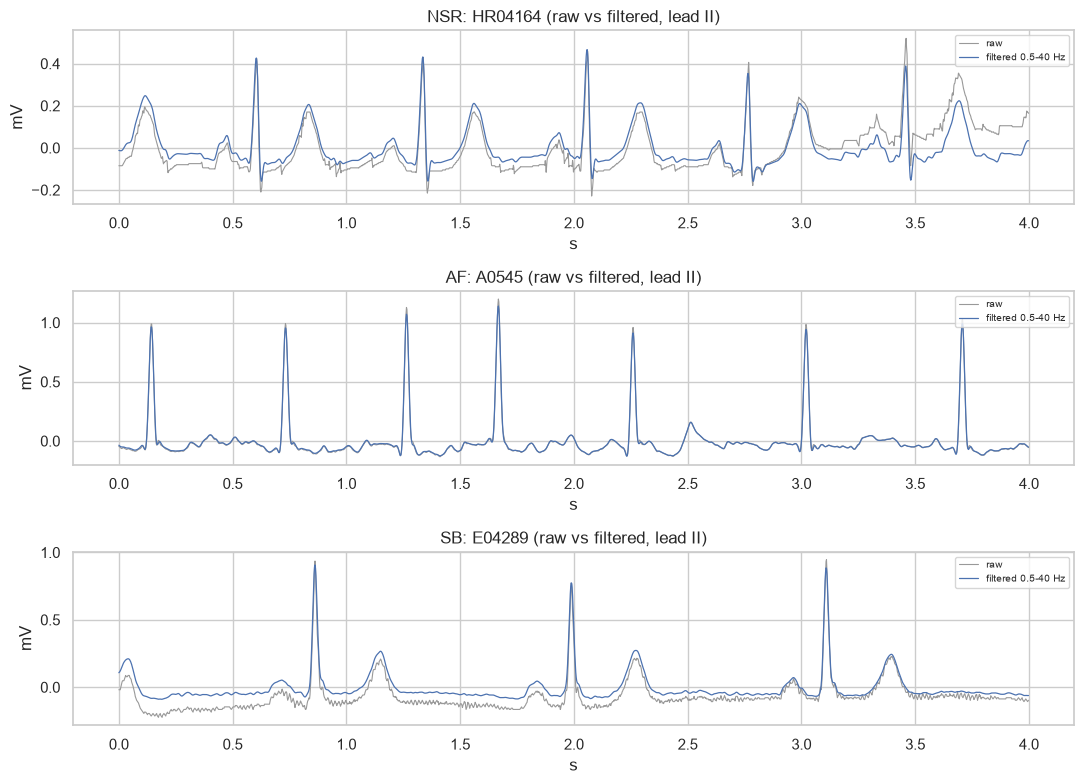

In [6]:
eda.before_after_preprocessing(meta, labels); plt.show()

## 5. Feature extraction

In [7]:
if not (DATA_DIR / "features.parquet").exists():
    from src.pipeline import build_features
    build_features(labels.record_id.tolist(), labels, "features", n_jobs=N_JOBS)   # ~100 s, per-record cache => resumable
X = pd.read_parquet(DATA_DIR / "features.parquet")
diag = pd.read_parquet(DATA_DIR / "extraction_diag.parquet")
print(X.shape, "| inf values:", int(np.isinf(X).sum().sum()))
ft.failure_report(diag, labels).round(4)

(6541, 131) | inf values: 0


,n,no_peaks,delin_failed,pr_nan,qrs_nan,t_nan,p_nan
ALL,6541,0.0003,0.0008,0.0029,0.0014,0.0061,0.0008
AF,1093,0.0000,0.0000,0.0009,0.0000,0.0128,0.0000
IAVB,754,0.0000,0.0000,0.0013,0.0000,0.0027,0.0000
NSR,2000,0.0010,0.0010,0.0025,0.0015,0.0015,0.0010
PAC,627,0.0000,0.0000,0.0000,0.0000,0.0064,0.0000
RBBB,1611,0.0000,0.0019,0.0037,0.0031,0.0106,0.0019
SB,456,0.0000,0.0000,0.0132,0.0022,0.0000,0.0000
cpsc_2018,3933,0.0000,0.0005,0.0020,0.0010,0.0081,0.0005
cpsc_2018_extra,6,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
georgia,1144,0.0000,0.0009,0.0070,0.0017,0.0052,0.0009


In [8]:
print("Unreadable records (truncated .mat):", diag.index[diag.error != ""].tolist())
ft.data_dictionary().groupby("group").size().rename("n_features").to_frame()

Unreadable records (truncated .mat): ['HR09972', 'HR11696']


,n_features
group,
intervals,6
patient,2
per_lead,96
rhythm,12
spectral,8
wavelet,7


## 6. EDA

### 6.1 Class frequencies and 6.2 label co-occurrence

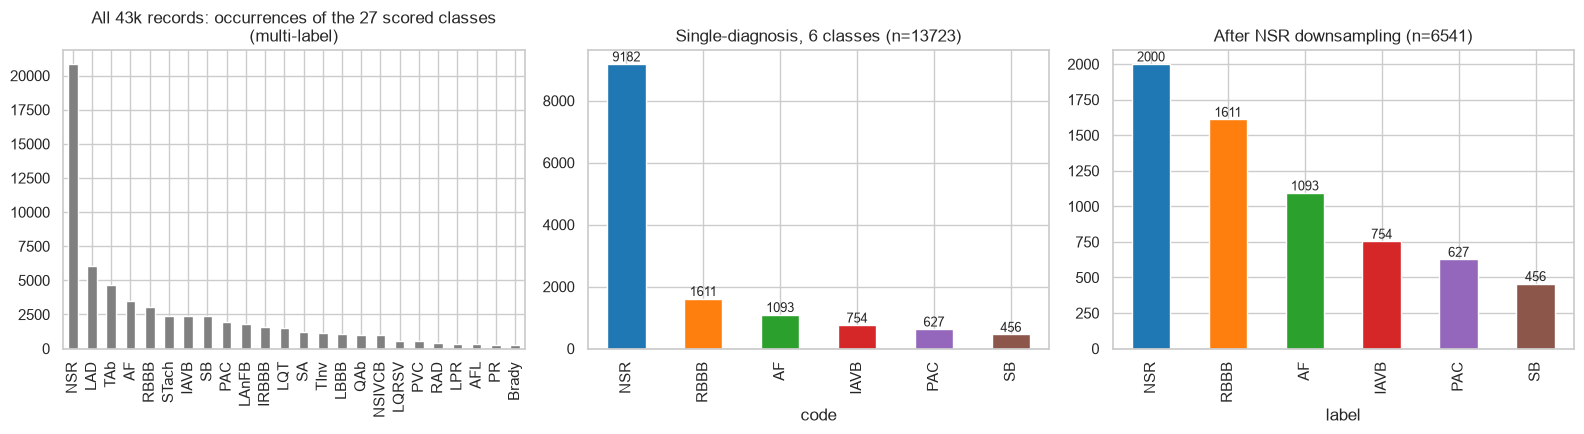

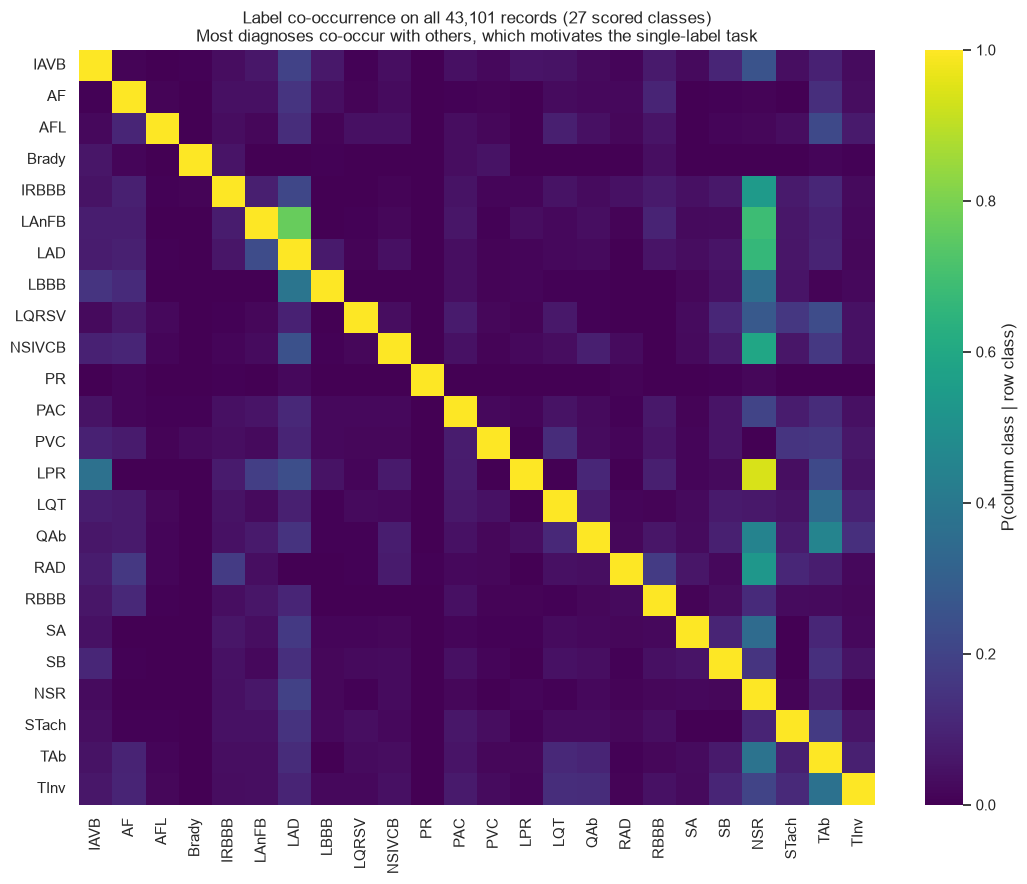

In [9]:
eda.class_frequencies(meta, labels); plt.show(); eda.cooccurrence(meta); plt.show()

### 6.3 Per-source distributions (multi-source shift)

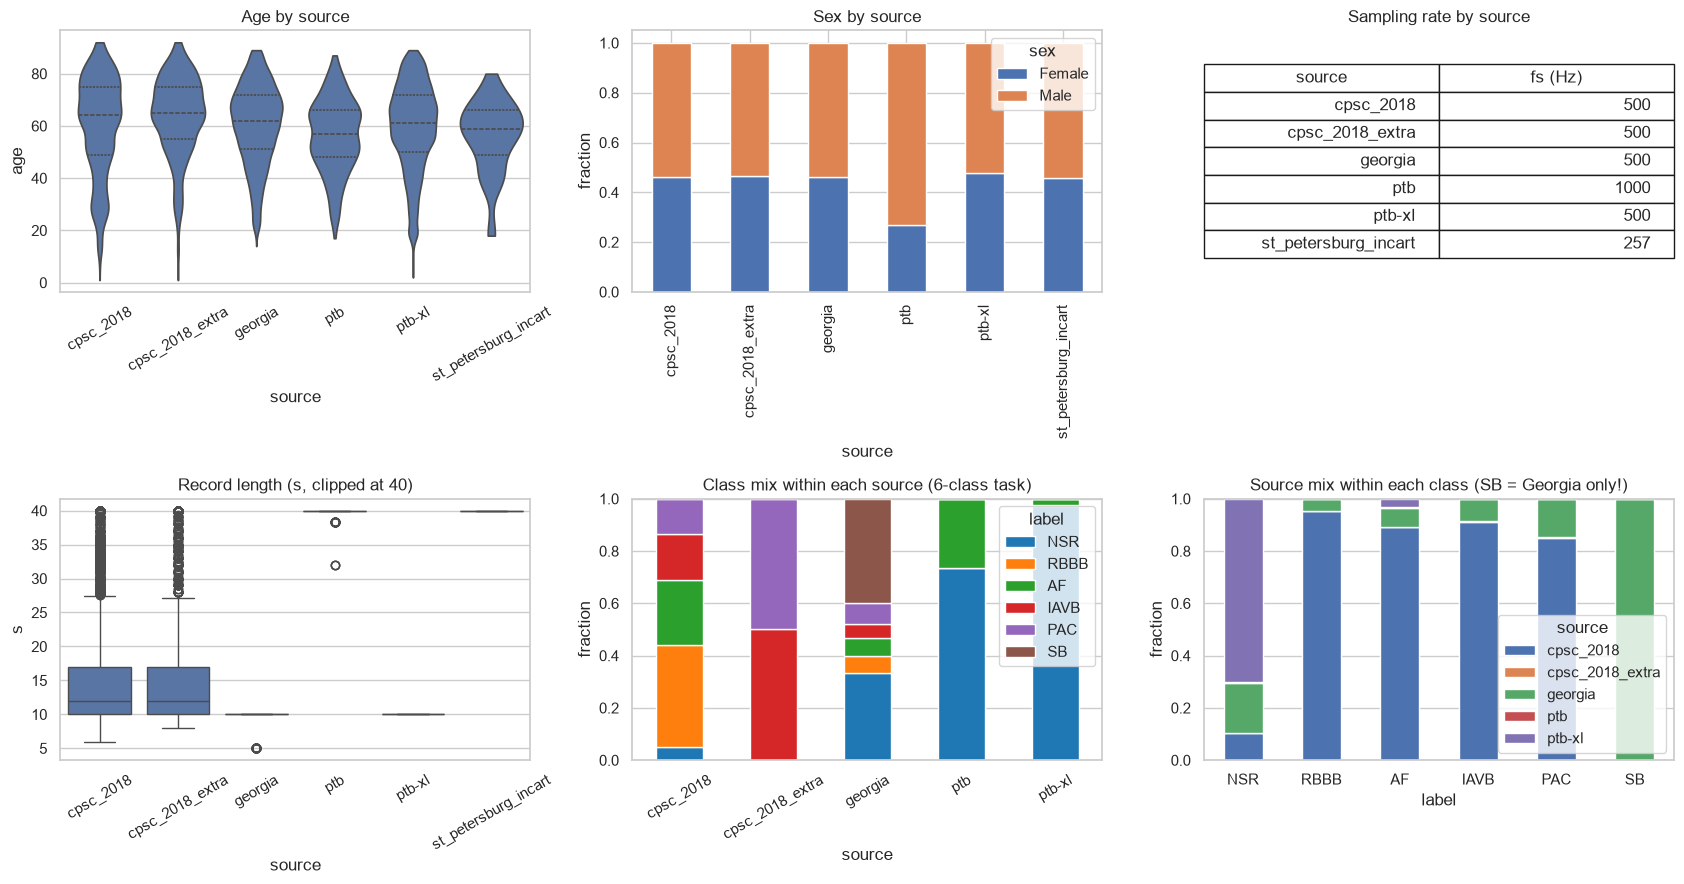

In [10]:
eda.source_distributions(meta, labels); plt.show()

**Key finding:** class and source are confounded (SB is only in Georgia; NSR is mostly PTB-XL; RBBB/IAVB/PAC mostly CPSC). Splits stratify by class only, so accuracy partly reflects source cues; reported as a limitation.

### 6.4 Missing values

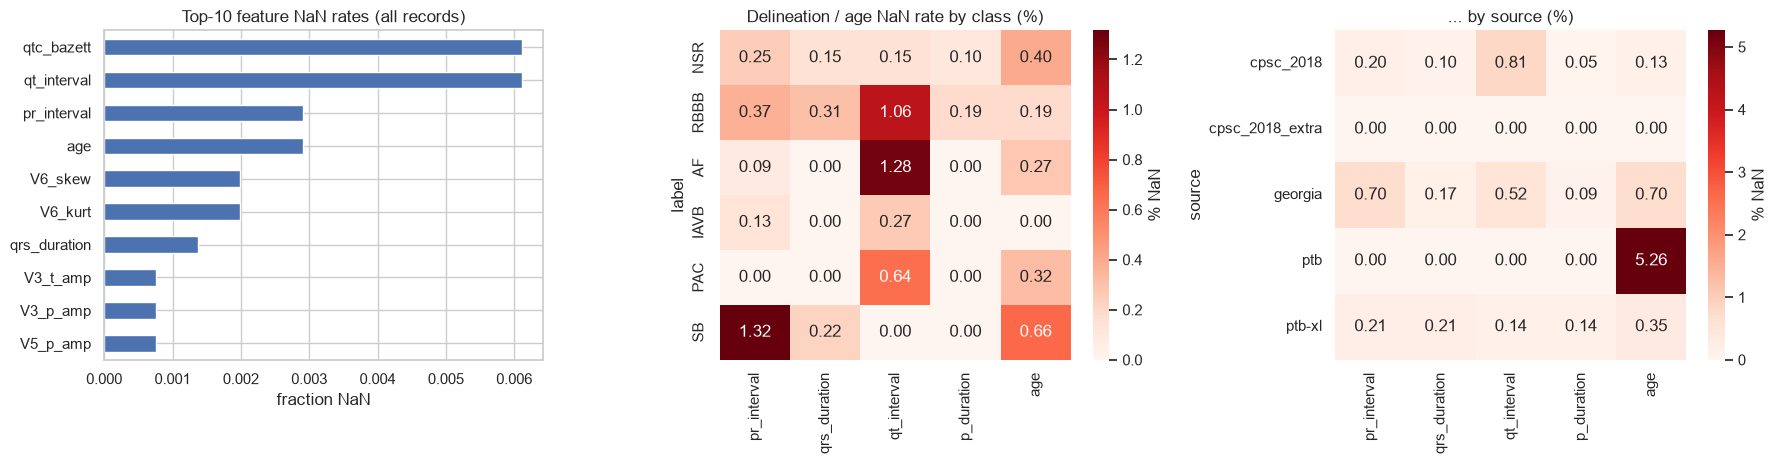

In [11]:
eda.missingness(X, labels, meta); plt.show()

### 6.5 Noise and QC

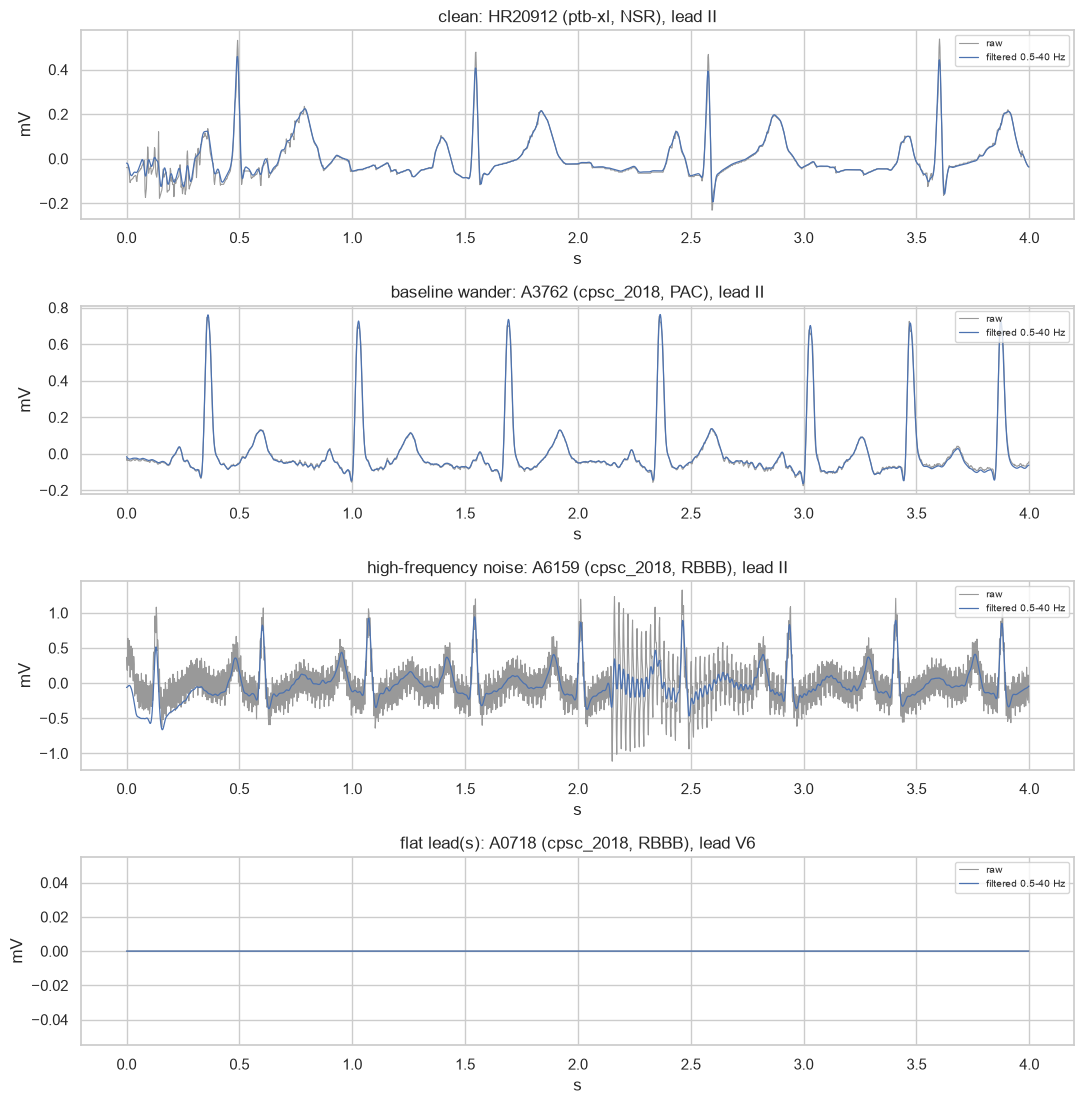

,% with flat lead,% with noisy lead (>25% HF power),% shorter than 10 s (zero-padded)
ALL,0.198746,1.834582,0.229393
AF,0.457457,2.470265,0.091491
IAVB,0.265252,2.122016,0.132626
NSR,0.05,1.15,0.2002
PAC,0.15949,2.870813,0.318979
RBBB,0.18622,1.800124,0.18622
SB,0.219298,1.535088,0.877193
cpsc_2018,0.279685,2.237478,0.177981
cpsc_2018_extra,0.0,16.666667,0.0
georgia,0.174825,1.835664,0.699301


In [12]:
eda.noise_examples(meta, diag, labels); plt.show(); eda.qc_rates(diag, labels)

### 6.6 Delineation overlay (one record per class)

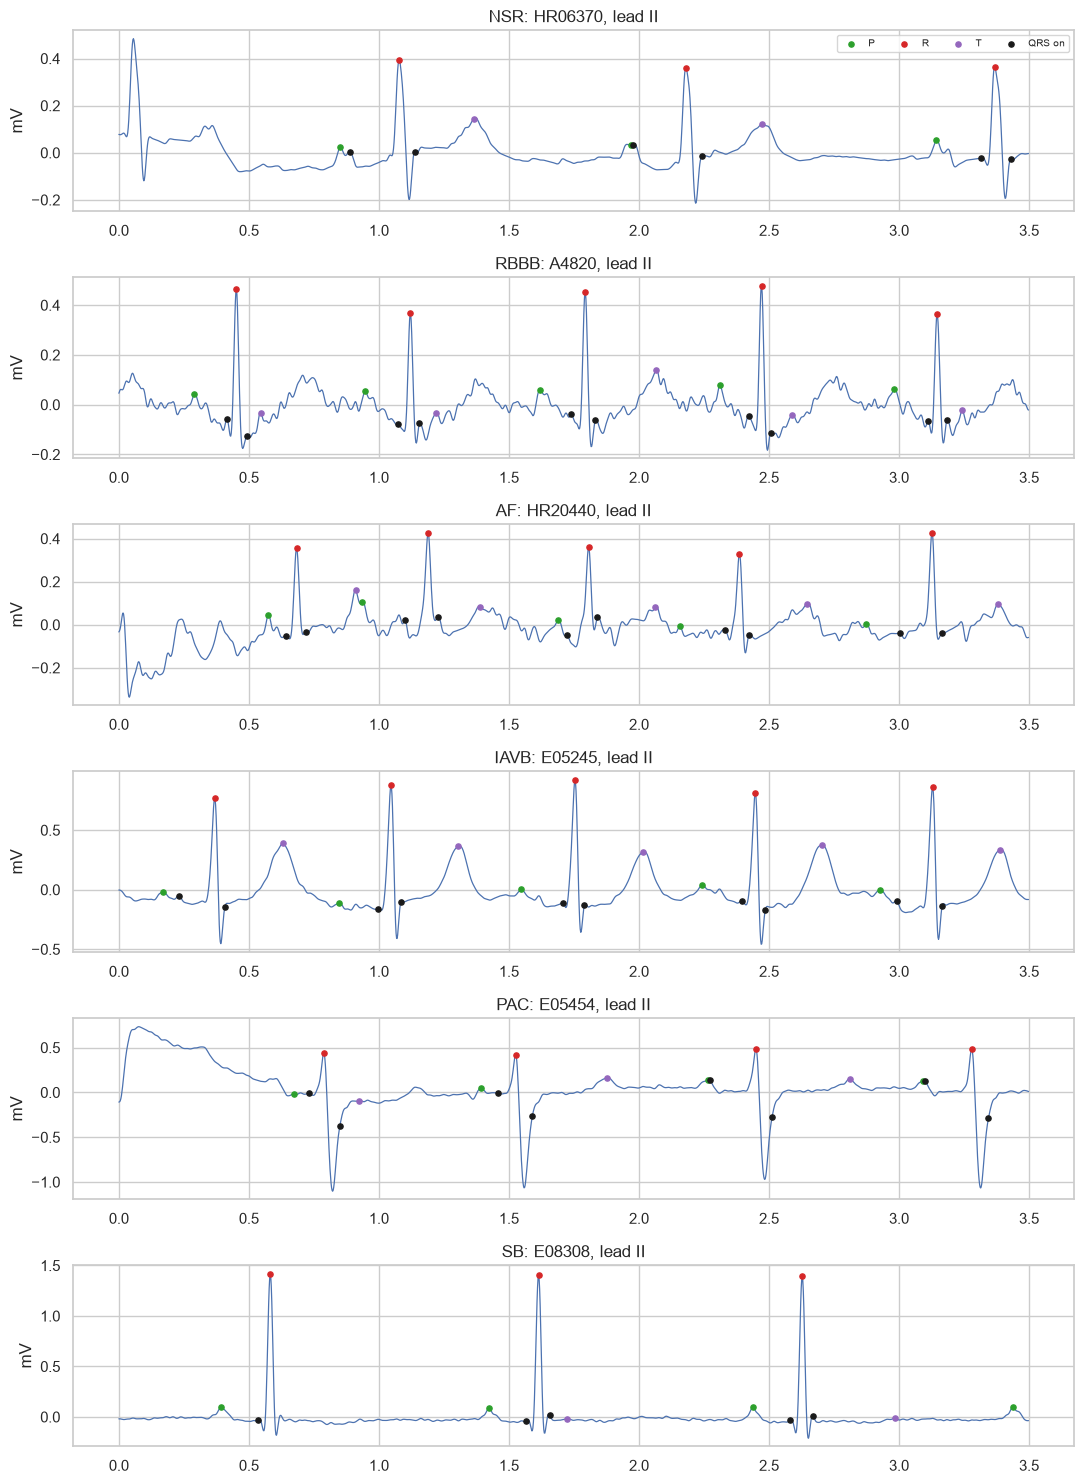

In [13]:
eda.delineation_overlay(meta, labels); plt.show()

### 6.7 Feature correlation and class-conditional key features (clinical sanity check)

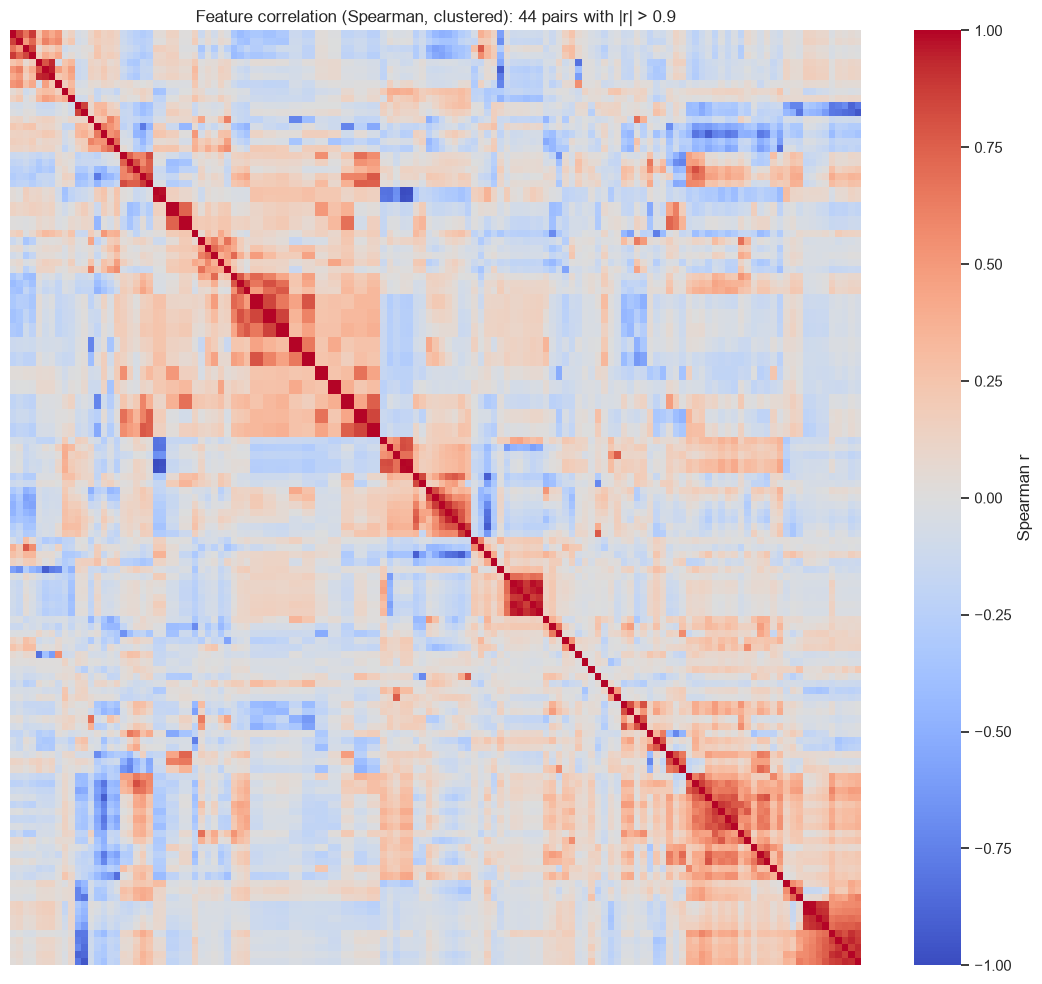

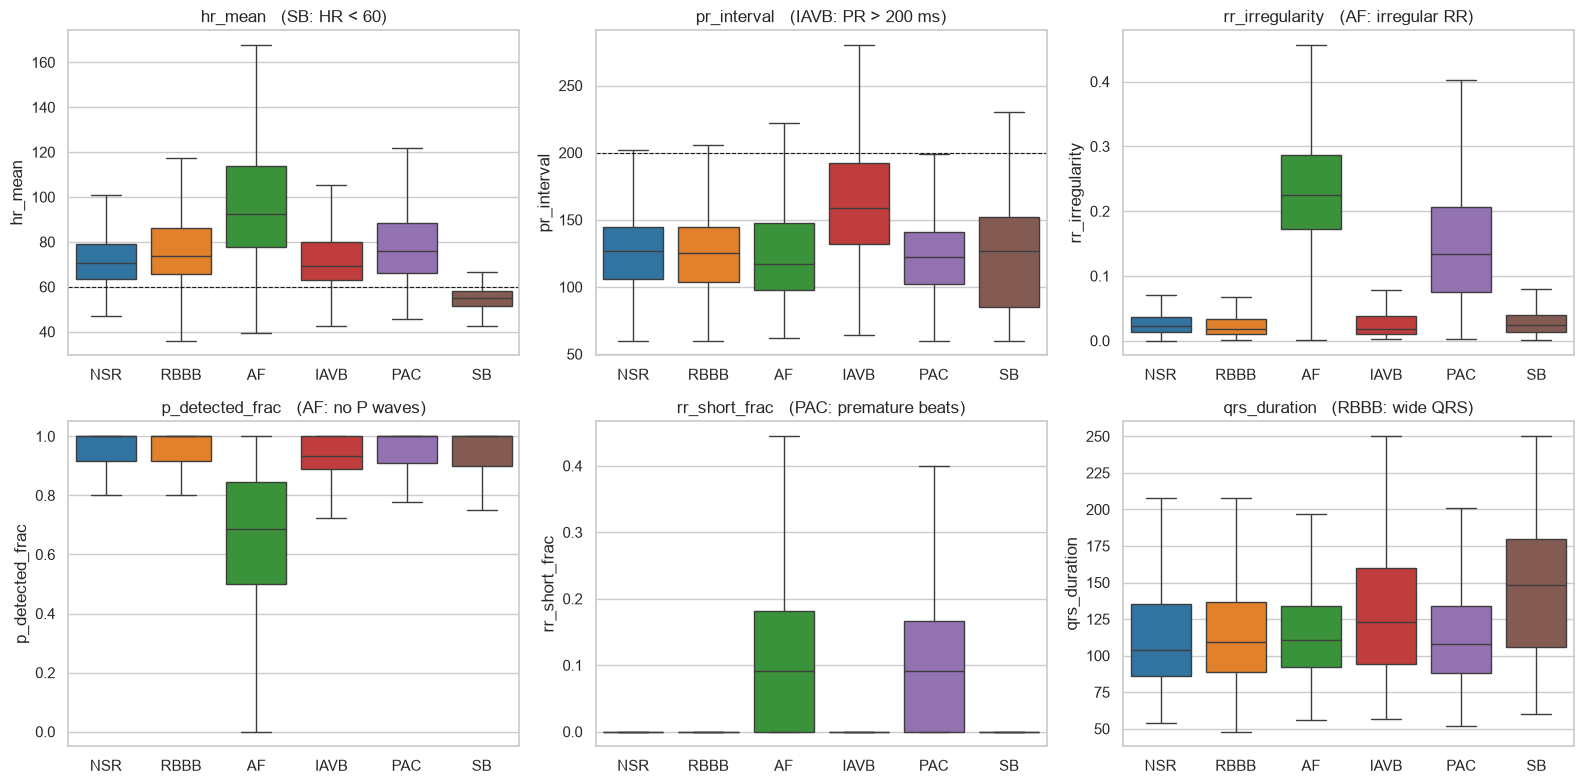

In [14]:
eda.correlation_heatmap(X); plt.show(); eda.key_feature_distributions(X, labels); plt.show()

## 7. Dummy baselines

In [15]:
X_all, y_all, splits = ev.load_task()
Xtr, ytr = ev.train_part(X_all, y_all, splits)
base_path = MODELS_DIR / "baselines.csv"
if not base_path.exists():
    for r in ev.dummy_baseline(Xtr, ytr, splits["folds"]): ev.append_result(r, base_path)
eda.baseline_table()

,name,accuracy_val_mean,accuracy_val_std,f1_macro_val_mean,f1_macro_val_std
0,dummy_stratified,0.213,0.012,0.166,0.01
1,dummy_most_frequent,0.306,0.000,0.078,0.00


In [16]:
DUMMY_F1 = float(pd.read_csv(base_path).query("name=='dummy_stratified'").f1_macro_val_mean.iloc[0]); DUMMY_F1

0.166124937683482

## 8. Models on feature set (a): all 131 features
Shared 5 folds inside the 80%. Grids are small and fixed; best config by CV macro-F1. Round 2 adds stronger regularisation for models flagged **overfit** in round 1 (train − CV macro-F1 > 0.10).

In [17]:
if RUN_HEAVY:
    for rnd in ("r1", "r2"):
        subprocess.run([sys.executable, "scripts/run_models.py", "a", "all", rnd], cwd=PROJECT_ROOT, check=True,
                       env={**os.environ, "PYTHONPATH": str(PROJECT_ROOT), "PYTHONWARNINGS": "ignore"})
grid_a = pd.read_csv(MODELS_DIR / "grid_results_a.csv")
grid_a.assign(cv=lambda d: d.f1_macro_val_mean.round(3), train=lambda d: d.f1_macro_train_mean.round(3))[
    ["model", "round", "params", "cv", "train", "flag", "wall_s"]].sort_values(["model", "cv"], ascending=[True, False]).groupby("model").head(4)

,model,round,params,cv,train,flag,wall_s
31,knn,r2,"{'clf__n_neighbors': 5, 'clf__p': 1}",0.617,1.000,overfit,6.871388
5,knn,r1,{'clf__n_neighbors': 5},0.602,1.000,overfit,0.830685
4,knn,r1,{'clf__n_neighbors': 3},0.600,1.000,overfit,0.938731
32,knn,r2,"{'clf__n_neighbors': 11, 'clf__p': 1}",0.595,1.000,overfit,3.927070
55,lgbm,r2,"{'clf__num_leaves': 15, 'clf__learning_rate': ...",0.796,0.979,overfit,13.353552
23,lgbm,r1,"{'clf__num_leaves': 15, 'clf__learning_rate': ...",0.795,0.979,overfit,8.861138
57,lgbm,r2,"{'clf__num_leaves': 15, 'clf__learning_rate': ...",0.795,0.979,overfit,18.856436
53,lgbm,r2,"{'clf__num_leaves': 7, 'clf__learning_rate': 0...",0.793,0.975,overfit,12.457930
2,logreg,r1,{'clf__C': 1},0.762,0.833,ok,0.775424
1,logreg,r1,{'clf__C': 0.1},0.761,0.811,ok,0.507349


In [18]:
best_a = md_.best_per_model("a")
best_a[["model", "params", "f1_macro_val_mean", "f1_macro_val_std", "accuracy_val_mean", "roc_auc_macro_val_mean",
        "f1_macro_train_mean", "gap_f1_macro", "flag", "fit_s_mean"]].round(3)

,model,params,f1_macro_val_mean,f1_macro_val_std,accuracy_val_mean,roc_auc_macro_val_mean,f1_macro_train_mean,gap_f1_macro,flag,fit_s_mean
0,logreg,{'clf__C': 1},0.762,0.012,0.795,0.953,0.833,0.071,ok,0.430
1,knn,"{'clf__n_neighbors': 5, 'clf__p': 1}",0.617,0.028,0.712,0.882,1.000,0.383,overfit,0.125
2,svm,"{'clf__C': 3, 'clf__gamma': 'scale'}",0.766,0.011,0.803,0.963,0.940,0.174,overfit,3.584
3,rf,"{'clf__max_depth': 16, 'clf__min_samples_leaf'...",0.747,0.003,0.783,0.951,0.985,0.238,overfit,0.965
4,lgbm,"{'clf__num_leaves': 15, 'clf__learning_rate': ...",0.796,0.006,0.826,0.969,0.979,0.184,overfit,2.308
5,mlp,"{'clf__hidden_layer_sizes': (128, 64), 'clf__a...",0.764,0.009,0.807,0.959,0.876,0.112,overfit,1.268


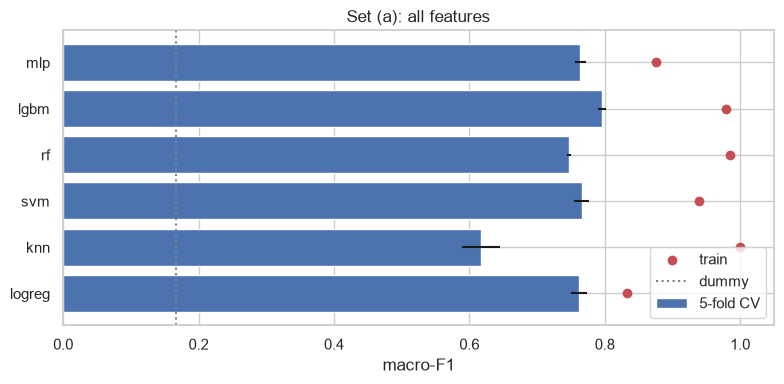

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
b = best_a.set_index("model")
ax.barh(b.index.astype(str), b.f1_macro_val_mean, xerr=b.f1_macro_val_std, color="C0", label="5-fold CV")
ax.scatter(b.f1_macro_train_mean, b.index.astype(str), color="C3", zorder=3, label="train")
ax.axvline(DUMMY_F1, color="gray", ls=":", label="dummy"); ax.set(xlabel="macro-F1", title="Set (a): all features"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "08_models_set_a.png", dpi=150); plt.show()

## 9. Sets (b) M2's reduced representation and (c) M3's selected features
Same six models, grids, folds and metrics. Set (b) = M2's best reducer (impute, scale, clip, LDA with 5 components), fit inside each training fold. Set (c) = M3's 59 features (RFECV with logistic regression). Grids: `python scripts/run_models.py b|c all r1|r2`; one-time test scoring: `python scripts/score_test_bc.py`.

In [20]:
names = ["logreg", "knn", "svm", "rf", "lgbm", "mlp"]
best_set = {fs: md_.best_per_model(fs).assign(model=lambda d: d.model.astype(str)).set_index("model") for fs in "abc"}
sel = json.loads((DATA_DIR / "selected_features.json").read_text())
print("set (c):", sel["label"], "-", len(sel["features"]), "features |", "set (b): ", json.loads((MODELS_DIR / "m2" / "best_reducer.json").read_text())["best"]["method"], "-> 5 dims")
tr = pd.read_csv(MODELS_DIR / "test_results.csv").set_index("name")
cmp_bc = pd.DataFrame({
    **{f"CV F1 ({fs})": [best_set[fs].loc[m, "f1_macro_val_mean"] for m in names] for fs in "abc"},
    **{f"train-CV gap ({fs})": [best_set[fs].loc[m, "gap_f1_macro"] for m in names] for fs in "abc"},
    **{f"flag ({fs})": [best_set[fs].loc[m, "flag"] for m in names] for fs in "abc"},
    **{f"TEST F1 ({fs})": [tr.loc[f"{m}|{fs}", "f1_macro"] for m in names] for fs in "abc"},
}, index=names).round(3)
cmp_bc.to_csv(MODELS_DIR / "table_cv_test_sets_abc.csv")
cmp_bc

set (c): RFECV (LogReg) - 59 features | set (b):  LDA -> 5 dims


,CV F1 (a),CV F1 (b),CV F1 (c),train-CV gap (a),train-CV gap (b),train-CV gap (c),flag (a),flag (b),flag (c),TEST F1 (a),TEST F1 (b),TEST F1 (c)
logreg,0.762,0.763,0.781,0.071,0.029,0.027,ok,ok,ok,0.771,0.765,0.766
knn,0.617,0.767,0.661,0.383,0.233,0.339,overfit,overfit,overfit,0.613,0.767,0.651
svm,0.766,0.768,0.780,0.174,0.023,0.143,overfit,ok,overfit,0.776,0.768,0.778
rf,0.747,0.763,0.751,0.238,0.163,0.228,overfit,overfit,overfit,0.748,0.777,0.745
lgbm,0.796,0.761,0.793,0.184,0.061,0.179,overfit,ok,overfit,0.803,0.763,0.796
mlp,0.764,0.768,0.776,0.112,0.034,0.102,overfit,ok,overfit,0.785,0.778,0.769


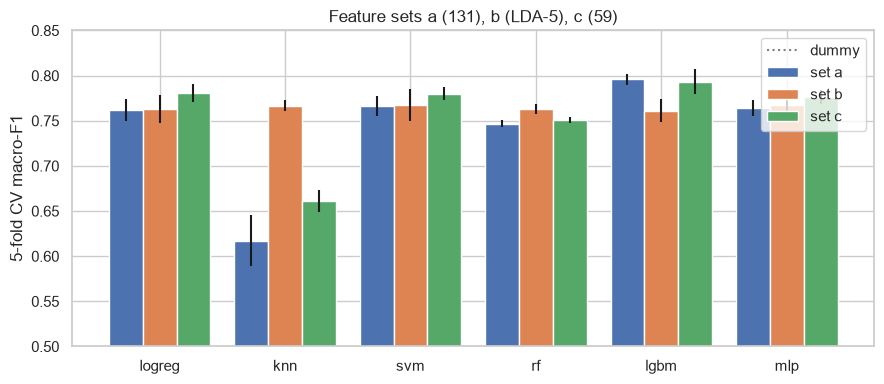

In [21]:
fig, ax = plt.subplots(figsize=(9, 4)); w = 0.27; x = np.arange(len(names))
for i, fs in enumerate("abc"):
    ax.bar(x + (i - 1) * w, [best_set[fs].loc[m, "f1_macro_val_mean"] for m in names], w,
           yerr=[best_set[fs].loc[m, "f1_macro_val_std"] for m in names], label=f"set {fs}")
ax.axhline(DUMMY_F1, color="gray", ls=":", label="dummy"); ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0.5, 0.85); ax.set_ylabel("5-fold CV macro-F1"); ax.legend(); ax.set_title("Feature sets a (131), b (LDA-5), c (59)")
fig.tight_layout(); fig.savefig(FIG / "09_models_sets_abc.png", dpi=150); plt.show()

## 10. Final evaluation on the 20% test set
Each chosen model (best CV config per model) is refit on the full 80% and scored on the test set **once** (`ev.fit_and_test` refuses repeats; every call is logged in `results/test_log.csv`). Test numbers never fed back into any choice.

In [22]:
done = set(pd.read_csv(ev.TEST_LOG).name) if ev.TEST_LOG.exists() else set()
for _, r in best_a.iterrows():
    name = f"{r.model}|a"
    if name in done: continue                         # already scored once; do not repeat
    out = ev.fit_and_test(md_.make_model(str(r.model), r.params_dict), X_all, y_all, splits, name)
    out["metrics"].update(name=name, model=str(r.model), feature_set="a")
    ev.append_result({**out["metrics"], "cv_f1_macro": r.f1_macro_val_mean, "train_f1_macro": r.f1_macro_train_mean,
                      "params": r.params}, MODELS_DIR / "test_results.csv")
test_tbl = pd.read_csv(MODELS_DIR / "test_results.csv")
test_tbl[["name", "accuracy", "error_rate", "f1_macro", "f1_weighted", "precision_macro", "recall_macro",
          "roc_auc_macro", "roc_auc_weighted", "cv_f1_macro", "train_f1_macro"]].round(3)

,name,accuracy,error_rate,f1_macro,f1_weighted,precision_macro,recall_macro,roc_auc_macro,roc_auc_weighted,cv_f1_macro,train_f1_macro
0,logreg|a,0.803,0.197,0.771,0.806,0.759,0.789,0.959,0.961,0.762,0.833
1,knn|a,0.713,0.287,0.613,0.691,0.697,0.591,0.886,0.904,0.617,1.000
2,svm|a,0.811,0.189,0.776,0.812,0.770,0.788,0.966,0.968,0.766,0.940
3,rf|a,0.783,0.217,0.748,0.785,0.742,0.769,0.950,0.953,0.747,0.985
4,lgbm|a,0.832,0.168,0.803,0.832,0.801,0.808,0.970,0.972,0.796,0.979
5,mlp|a,0.821,0.179,0.785,0.820,0.791,0.785,0.962,0.965,0.764,0.876
6,logreg|b,0.794,0.206,0.765,0.798,0.754,0.788,0.953,0.955,0.763,0.792
7,knn|b,0.805,0.195,0.767,0.803,0.780,0.758,0.947,0.953,0.767,1.000
8,svm|b,0.797,0.203,0.768,0.801,0.758,0.794,0.957,0.959,0.768,0.791
9,rf|b,0.810,0.190,0.777,0.812,0.770,0.789,0.954,0.956,0.763,0.926


In [23]:
final = test_tbl[test_tbl.name.str.endswith("|a")].sort_values("cv_f1_macro", ascending=False).iloc[0]   # chosen by CV, not by test
print("Final model for set (a), chosen by CV macro-F1:", final["name"], final["params"])

Final model for set (a), chosen by CV macro-F1: lgbm|a {'clf__num_leaves': 15, 'clf__learning_rate': 0.03, 'clf__min_child_samples': 20, 'clf__reg_lambda': 1.0}


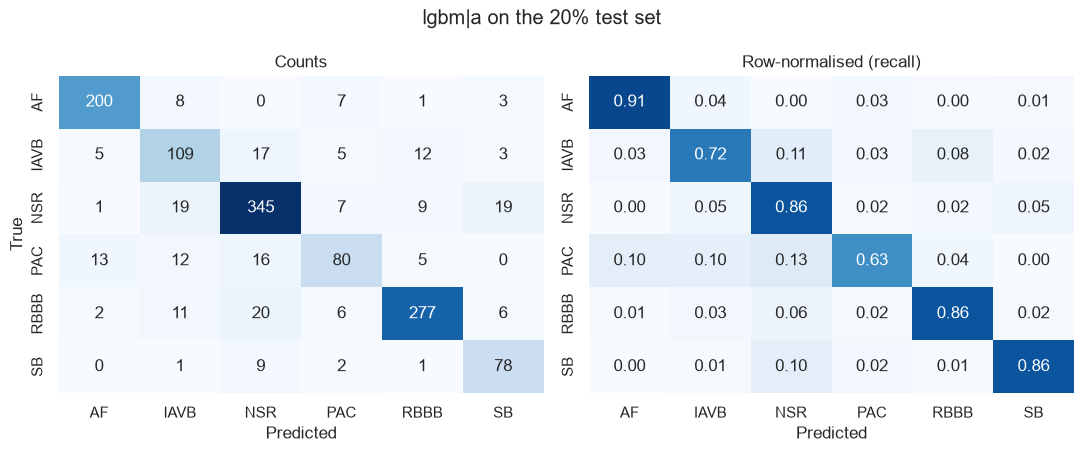

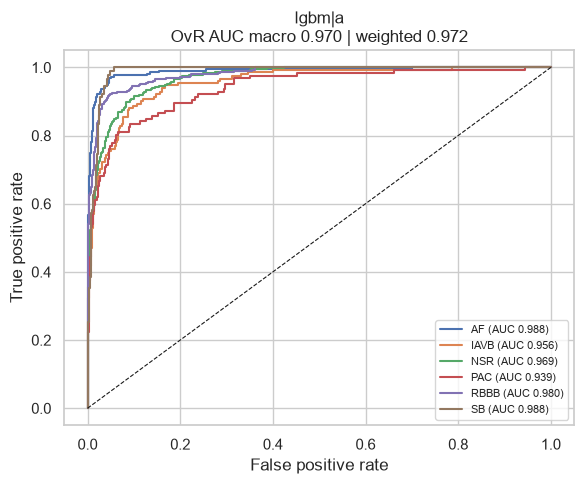

,precision,recall,f1,support
AF,0.905,0.913,0.909,219
IAVB,0.681,0.722,0.701,151
NSR,0.848,0.862,0.855,400
PAC,0.748,0.635,0.687,126
RBBB,0.908,0.860,0.884,322
SB,0.716,0.857,0.780,91


In [24]:
# Figures for the chosen model: deterministic refit; does NOT touch the test log or any selection.
from sklearn.base import clone
fm, fset = final["name"].split("|")
Xte, yte = ev.test_part(X_all, y_all, splits)
m = clone(md_.make_model(fm, ast.literal_eval(final["params"]))).fit(Xtr, ytr)
pr = m.predict_proba(Xte); yp = m.predict(Xte); classes = list(m.classes_)
raw, norm = ev.confusion(yte, yp, classes)
f = ev.confusion_figure(raw, norm, f"{final['name']} on the 20% test set"); f.savefig(FIG / "10_confusion_final.png", dpi=150); plt.show()
f = ev.roc_figure(yte, pr, classes, final["name"]); f.savefig(FIG / "10_roc_final.png", dpi=150); plt.show()
pc = ev.per_class_table(yte, yp, classes); pc.round(3).to_csv(MODELS_DIR / "per_class_final.csv"); pc.round(3)

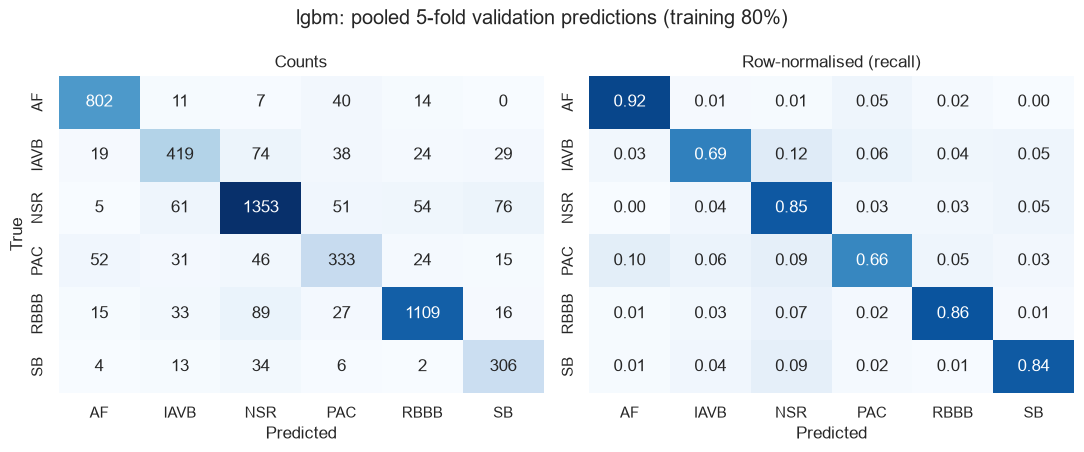

In [25]:
oof = pd.read_parquet(MODELS_DIR / f"oof_a_{fm}_r2.parquet" if (MODELS_DIR / f"oof_a_{fm}_r2.parquet").exists() else MODELS_DIR / f"oof_a_{fm}.parquet")
raw_cv, norm_cv = ev.confusion(oof["y_true"], oof["y_pred"], classes)
f = ev.confusion_figure(raw_cv, norm_cv, f"{fm}: pooled 5-fold validation predictions (training 80%)"); f.savefig(FIG / "10_confusion_cv.png", dpi=150); plt.show()

## 11. Over/underfitting diagnostics: learning and validation curves

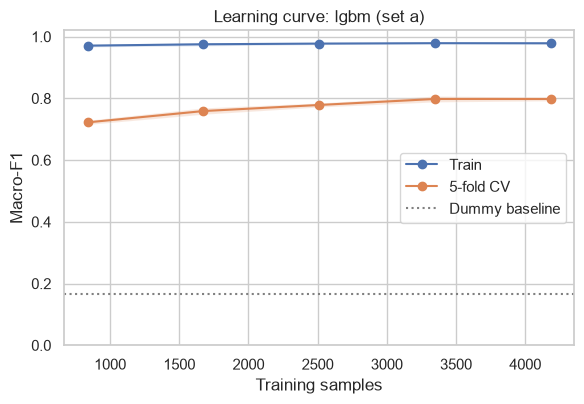

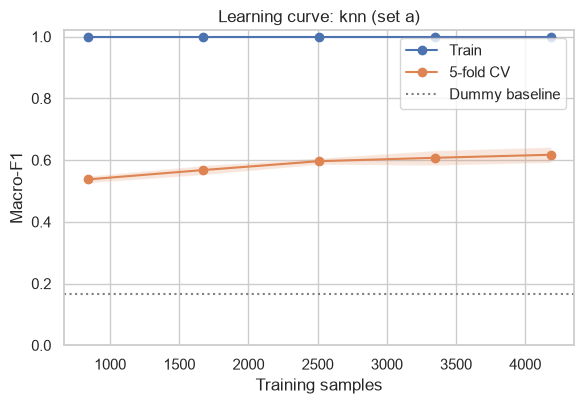

n_train  train_mean  train_std  val_mean  val_std
model                                                     
lgbm  0      837       0.971      0.004     0.722    0.007
      1     1674       0.975      0.005     0.759    0.010
      2     2511       0.978      0.003     0.779    0.007
      3     3348       0.979      0.002     0.798    0.010
      4     4185       0.979      0.003     0.798    0.006
knn   0      837       1.000      0.000     0.537    0.011
      1     1674       1.000      0.000     0.568    0.015
      2     2511       1.000      0.000     0.596    0.010
      3     3348       1.000      0.000     0.607    0.024
      4     4185       1.000      0.000     0.617    0.025

In [26]:
bm = best_a.assign(model=best_a.model.astype(str)).set_index("model")
most_overfit = bm.drop(index=fm).sort_values("gap_f1_macro", ascending=False).index[0]
lc_models = [fm, most_overfit]
lc = {}
for mname in lc_models:
    lc[mname] = ev.learning_curve_data(md_.make_model(mname, bm.loc[mname, "params_dict"]), Xtr, ytr, splits["folds"])
    f = ev.learning_curve_figure(lc[mname], f"Learning curve: {mname} (set a)", DUMMY_F1); f.savefig(FIG / f"11_learning_{mname}.png", dpi=150); plt.show()
pd.concat(lc, names=["model"]).round(3).to_csv(MODELS_DIR / "learning_curves.csv")
pd.concat(lc, names=["model"]).round(3)

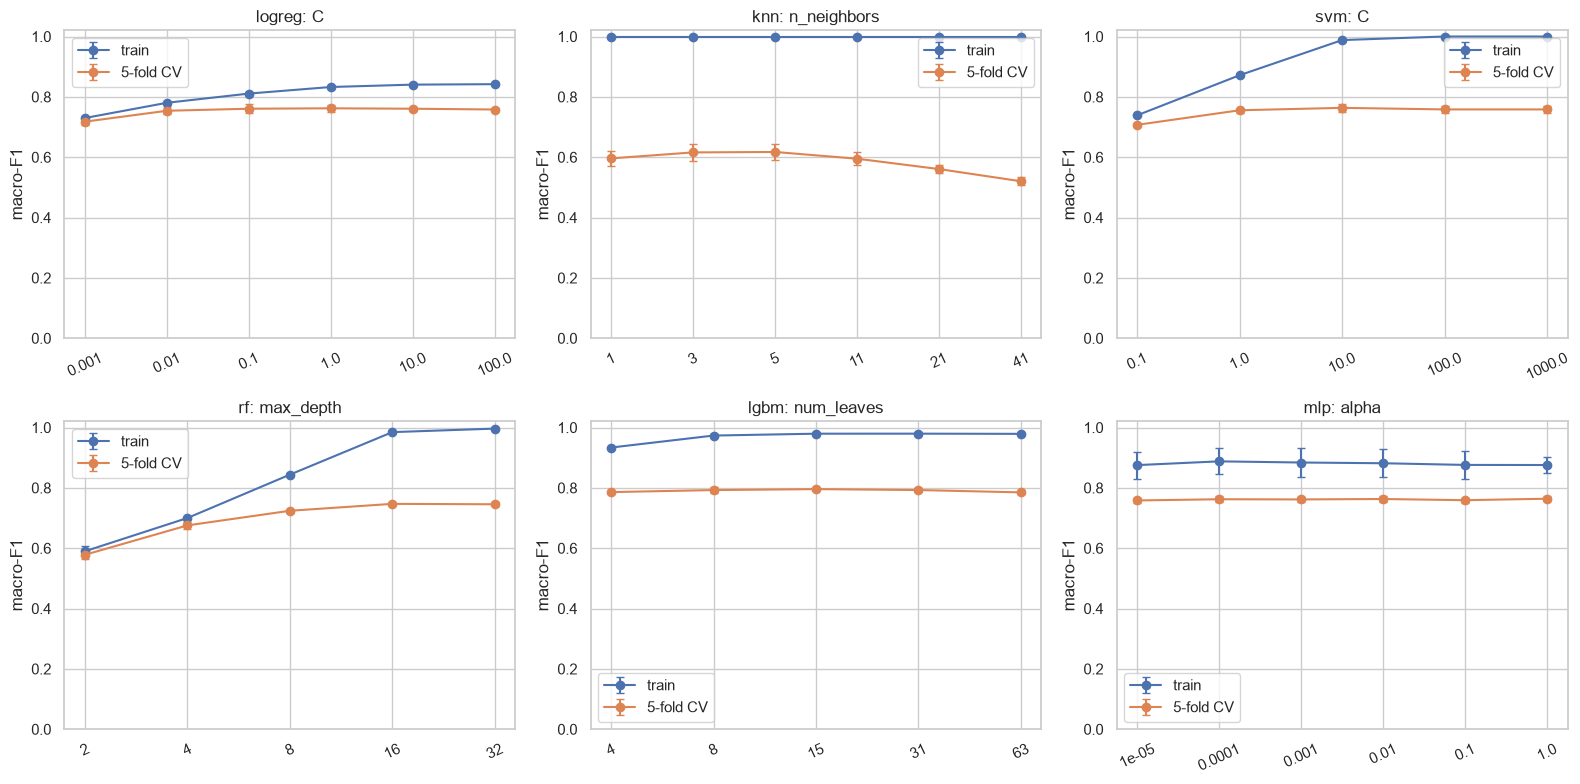

In [27]:
vc_rows = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, mname in zip(axes.ravel(), bm.index):
    param, _v = md_.MAIN_PARAM[mname]
    vc = md_.validation_curve_data(mname, bm.loc[mname, "params_dict"], Xtr, ytr, splits["folds"]); vc_rows[mname] = vc
    x = np.arange(len(vc))
    for col, lab_ in (("train", "train"), ("val", "5-fold CV")):
        ax.errorbar(x, vc[f"{col}_mean"], yerr=vc[f"{col}_std"], fmt="o-", capsize=3, label=lab_)
    ax.set_xticks(x, vc["value"].astype(str), rotation=25); ax.set(title=f"{mname}: {param.replace('clf__','')}", ylim=(0, 1.02), ylabel="macro-F1"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "11_validation_curves.png", dpi=150); plt.show()
pd.concat(vc_rows, names=["model"]).round(3).to_csv(MODELS_DIR / "validation_curves.csv")

### Discussion
See the tables above: round 1 vs round 2 gaps, the learning curves (does CV plateau while train stays higher?), and the validation curves (where the train/CV gap opens). The written interpretation goes in `report/sections/`.

## 12. Export for the report

In [28]:
summary = best_a[["model", "f1_macro_val_mean", "f1_macro_val_std", "accuracy_val_mean", "accuracy_val_std",
                  "roc_auc_macro_val_mean", "f1_macro_train_mean", "gap_f1_macro", "flag", "params"]].round(4)
summary.to_csv(MODELS_DIR / "table_cv_set_a.csv", index=False)
print("Saved tables to results/ and figures to", FIG)
sorted(p.name for p in FIG.glob("*.png"))

Saved tables to results/ and figures to C:\Ejust\7th Semster\New Trends in Data Science\Projects\Project 1\results\figures


['01_class_frequencies.png',
 '02_cooccurrence.png',
 '03_source_distributions.png',
 '04_missingness.png',
 '05_noise_examples.png',
 '06_delineation_overlay.png',
 '06b_before_after_preprocessing.png',
 '07_feature_correlation.png',
 '07b_key_feature_distributions.png',
 '08_models_set_a.png',
 '09_models_sets_abc.png',
 '10_confusion_cv.png',
 '10_confusion_final.png',
 '10_roc_final.png',
 '11_learning_knn.png',
 '11_learning_lgbm.png',
 '11_validation_curves.png',
 '20_pca_scree.png',
 '21_pca_loadings.png',
 '22_svd_vs_pca.png',
 '23_embeddings_true_class.png',
 '24_00_PCA_clusters.png',
 '24_01_LDA_clusters.png',
 '24_02_SVD_clusters.png',
 '24_03_KernelPCA_rbf_clusters.png',
 '24_04_KernelPCA_poly_clusters.png',
 '24_05_UMAP_clusters.png',
 '24_06_Isomap_clusters.png',
 '24_07_LLE_clusters.png',
 '24_08_LLE_modified_clusters.png',
 '24_09_SNE_clusters.png',
 '24_10_tSNE_p5_clusters.png',
 '24_11_tSNE_p30_clusters.png',
 '24_12_tSNE_p50_clusters.png',
 '24_13_MDS_metric_clusters